# Question 2: Motion or Memory?

## Stage 1: Environment and dataset verification

**Goal:** record the environment, load Moving MNIST, verify the prescribed video splits, and inspect one training video.

### 1. Import packages and record the environment

Use the installed packages initially. Recording their versions will help reproduce the experiments later.

In [1]:
import json
import platform
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
import torchvision
from torch.utils.data import Subset

environment = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "torch_cuda_version": torch.version.cuda,
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
}

print(json.dumps(environment, indent=2))

{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "matplotlib": "3.10.0",
  "cuda_available": true,
  "torch_cuda_version": "13.0",
  "gpu_name": "NVIDIA A100-SXM4-40GB"
}


### 2. Connect Drive and create storage folders

Approve Colab's Drive connection when prompted. This keeps the downloaded dataset and saved outputs available across runtime sessions.

The project files will be stored in `MyDrive/DL4STG_PA2`, with separate `data` and `outputs` folders. The environment information is saved as `environment_stage1.json`.

In [2]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL4STG_PA2")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for directory in (DATA_DIR, OUTPUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

environment_path = OUTPUT_DIR / "environment_stage1.json"
environment_path.write_text(
    json.dumps(environment, indent=2),
    encoding="utf-8",
)

print("Project folder:", PROJECT_DIR)
print("Dataset folder:", DATA_DIR)
print("Environment saved to:", environment_path)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/DL4STG_PA2
Dataset folder: /content/drive/MyDrive/DL4STG_PA2/data
Environment saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/environment_stage1.json


### 3. Download and inspect Moving MNIST

`split=None` returns complete videos. Torchvision's built-in `"train"` and `"test"` options split **frames within videos**, so we define our own video splits in the next cell.

Each returned video has axes **(time, channels, height, width)**. We expect 10,000 videos, each with shape `(20, 1, 64, 64)`.

The normalization function converts one video at a time to `float32` intensities in `[0, 1]`. This avoids making a float32 copy of the entire dataset.

See the [Torchvision MovingMNIST documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MovingMNIST.html).

In [3]:
def normalize_video(video):
    """Convert one uint8 video to float32 intensities in [0, 1]."""
    return video.to(dtype=torch.float32).div(255.0)


videos = torchvision.datasets.MovingMNIST(
    root=str(DATA_DIR),
    split=None,
    download=True,
    transform=normalize_video,
)

example_video = videos[0]

assert len(videos) == 10_000, "Unexpected number of videos."
assert example_video.shape == (20, 1, 64, 64), "Unexpected video shape."
assert example_video.dtype == torch.float32, "Unexpected dtype."
assert torch.isfinite(example_video).all(), "Found non-finite values."
assert 0.0 <= example_video.min().item()
assert example_video.max().item() <= 1.0

print("Number of videos:", len(videos))
print("One video shape:", tuple(example_video.shape))
print("Axis meanings: (time, channels, height, width)")
print("One video dtype:", example_video.dtype)
print(
    "Example intensity range:",
    (example_video.min().item(), example_video.max().item()),
)
print("Dataset checks passed.")

Number of videos: 10000
One video shape: (20, 1, 64, 64)
Axis meanings: (time, channels, height, width)
One video dtype: torch.float32
Example intensity range: (0.0, 1.0)
Dataset checks passed.


### 4. Define the prescribed video splits

Split by original **video index**, as required by the assignment:

| Split | Original video indices | Number of videos |
| --- | --- | --- |
| Training | 0-7,999 | 8,000 |
| Validation | 8,000-8,999 | 1,000 |
| Test | 9,000-9,999 | 1,000 |

`Subset` references selected videos in the original dataset without copying them. Training examples will be shuffled during training; these split memberships stay fixed.

In [4]:
train_videos = Subset(videos, range(0, 8_000))
val_videos = Subset(videos, range(8_000, 9_000))
test_videos = Subset(videos, range(9_000, 10_000))

assert (
    len(train_videos),
    len(val_videos),
    len(test_videos),
) == (8_000, 1_000, 1_000)

splits = {
    "train": train_videos,
    "validation": val_videos,
    "test": test_videos,
}

for name, subset in splits.items():
    first_index = subset.indices[0]
    last_index = subset.indices[-1]
    print(
        f"{name:10s}: {len(subset):5d} videos | "
        f"original indices {first_index}-{last_index}"
    )

print("Split checks passed.")

train     :  8000 videos | original indices 0-7999
validation:  1000 videos | original indices 8000-8999
test      :  1000 videos | original indices 9000-9999
Split checks passed.


### 5. Display all 20 frames of one training video

Python indexes frames from zero; the plot labels them **1-20**, matching the assignment.

Look for two handwritten digits moving across the frames. This is a dataset inspection plot; the assignment's **Figure 1** will be the optical-flow analysis later.

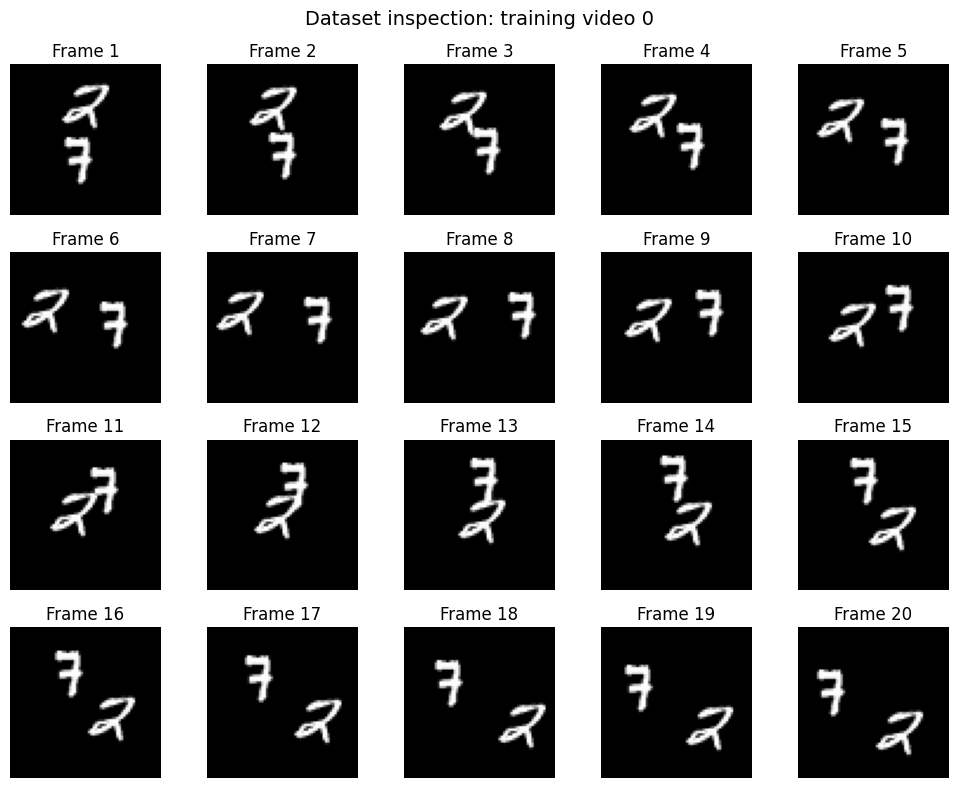

In [5]:
video = train_videos[0]

fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for frame_index, ax in enumerate(axes.flat):
    ax.imshow(
        video[frame_index, 0].numpy(),
        cmap="gray",
        vmin=0.0,
        vmax=1.0,
    )
    ax.set_title(f"Frame {frame_index + 1}")
    ax.axis("off")

fig.suptitle("Dataset inspection: training video 0", fontsize=14)
fig.tight_layout()
plt.show()

## Stage 2: Transformations, forecasting windows, and Table 1

**Goal:** implement the same functions that later training and evaluation will call, and verify every check in Table 1 (assignment pages 5-6).

### 6. Define mirror and rotation

Only the last two axes are spatial: `(..., height, width)`. All leading axes, such as time, channel, or batch, keep their order.

- `mirror(x)` flips the width axis, giving a left-right reflection.
- `rotate(x)` applies one 90-degree anticlockwise rotation.
- `rotate(x, k=-1)` applies the inverse rotation.

These functions work on a full video or a batch of windows without changing frame order. They rearrange intensities without interpolation.

References: [torch.flip](https://docs.pytorch.org/docs/2.11/generated/torch.flip.html) and [torch.rot90](https://docs.pytorch.org/docs/2.11/generated/torch.rot90.html).

In [6]:
def mirror(x):
    """Reflect the last spatial axis (width); preserve leading axes."""
    return torch.flip(x, dims=(-1,))


def rotate(x, k=1):
    """Rotate the last two spatial axes anticlockwise k quarter-turns."""
    return torch.rot90(x, k=k, dims=(-2, -1))

### 7. Define valid starts and forecasting windows

`start` uses the assignment's **one-based frame numbers**. Conversion to Python's zero-based indices happens inside `make_window`.

For speed `k` and start `t`:

- Input frames: `t, t+k, ..., t+4k`.
- Candidate target frames: `t+5k, ..., t+9k`.
- A target exists only if its frame number is at most 20.

Two training protocols use different allowed starts:

| Protocol | Speed | Allowed starts |
| --- | --- | --- |
| Normal-speed training (A and B) | 1 | 1-11 |
| Speed-augmented training (C and D) | 1 | 1-14 |
| Speed-augmented training (C and D) | 2 | 1-8 |
| Speed-augmented training (C and D) | 3 | 1-2 |

The latest required frame is `t + 9k` when all five targets are required, and `t + 6k` when at least two targets are required. This gives the allowed ranges above.

`make_window` returns:

| Return value | Shape | Meaning |
| --- | --- | --- |
| `inputs` | `(5, 1, 64, 64)` | Five observed frames |
| `targets` | `(5, 1, 64, 64)` | Available targets followed by zero placeholders |
| `target_mask` | `(5,)` | Boolean indicator of which targets exist |

**The zero placeholders are not observations.** Fixed target shapes let different speeds share a batch; the mask must exclude placeholders from every loss and metric. At 3x and `start=1`, the mask is `[True, True, False, False, False]`.

Later training code must sample starts from the appropriate protocol. The window function permits any start with five inputs and at least two real targets; this includes the extra starts needed by C and D.

In [7]:
def allowed_start_frames(speed=1, speed_augmented=False):
    """Return valid one-based starts for the specified training protocol."""
    if speed not in (1, 2, 3):
        raise ValueError("speed must be 1, 2, or 3.")
    if not speed_augmented and speed != 1:
        raise ValueError("Normal-speed training permits only speed=1.")

    last_required_offset = 6 if speed_augmented else 9
    last_start = 20 - last_required_offset * speed
    return range(1, last_start + 1)


def window_frame_numbers(start=1, speed=1):
    """Return real input/target frame numbers, using frames 1-20."""
    if not isinstance(start, int) or start < 1:
        raise ValueError("start must be a positive integer frame number.")
    if speed not in (1, 2, 3):
        raise ValueError("speed must be 1, 2, or 3.")

    input_frames = [start + i * speed for i in range(5)]
    target_frames = [
        start + i * speed
        for i in range(5, 10)
        if start + i * speed <= 20
    ]

    if input_frames[-1] > 20 or len(target_frames) < 2:
        raise ValueError("A window needs five inputs and at least two targets.")

    return input_frames, target_frames


def make_window(video, start=1, speed=1):
    """Return five inputs, five padded targets, and a valid-target mask."""
    if tuple(video.shape) != (20, 1, 64, 64):
        raise ValueError("Expected a video with shape (20, 1, 64, 64).")

    input_frames, target_frames = window_frame_numbers(start, speed)
    input_indices = [frame - 1 for frame in input_frames]
    target_indices = [frame - 1 for frame in target_frames]

    inputs = video[input_indices]
    targets = video.new_zeros((5, *video.shape[1:]))
    targets[:len(target_indices)] = video[target_indices]
    target_mask = (
        torch.arange(5, device=video.device) < len(target_indices)
    )

    return inputs, targets, target_mask

### 8. Run the exact Table 1 checks

Use the random video, single-pixel marker, and frame-number video specified in the assignment. Marker coordinates use **zero-based indices**, while the window checks use frame numbers **1-20**.

For (a)-(c), both conditions must hold:

1. Maximum absolute difference is exactly zero.
2. `torch.equal` returns `True`.

Marker checks distinguish a width flip from a height flip and anticlockwise rotation from clockwise rotation. Frame-number checks detect incorrect temporal selection.

The checks call the functions defined above; later experiments will reuse those same functions.

In [8]:
import pandas as pd
from IPython.display import display

table1_rows = []
exact_equality_checks = {}


def check_exact(label, actual, expected):
    max_difference = (actual - expected).abs().max().item()
    equal = torch.equal(actual, expected)

    table1_rows.append({
        "Check": label,
        "Expected": 0,
        "Yours": max_difference,
    })
    exact_equality_checks[label] = equal

    assert max_difference == 0.0, f"{label}: nonzero difference."
    assert equal, f"{label}: torch.equal returned False."


torch.manual_seed(0)
random_video = torch.rand(20, 1, 64, 64)

check_exact(
    "(a) max|M(M(x)) - x|",
    mirror(mirror(random_video)),
    random_video,
)

rotated_four_times = random_video
for _ in range(4):
    rotated_four_times = rotate(rotated_four_times)

check_exact(
    "(b) max|R^4(x) - x|",
    rotated_four_times,
    random_video,
)
check_exact(
    "(c) max|MRM(x) - R^-1(x)|",
    mirror(rotate(mirror(random_video))),
    rotate(random_video, k=-1),
)

marker_video = torch.zeros(20, 1, 64, 64)
marker_video[7, 0, 10, 20] = 1

for label, transformed, expected_location in [
    ("(d) bright pixel of M(p)", mirror(marker_video), (7, 10, 43)),
    ("(e) bright pixel of R(p)", rotate(marker_video), (7, 43, 10)),
]:
    positions = torch.nonzero(transformed, as_tuple=False)
    assert tuple(positions.shape) == (1, 4), "Expected one bright pixel."
    frame, channel, row, column = positions[0].tolist()
    actual_location = (frame, row, column)

    assert channel == 0
    assert actual_location == expected_location, label

    table1_rows.append({
        "Check": label,
        "Expected": str(expected_location),
        "Yours": str(actual_location),
    })

frame_number_video = (
    torch.arange(1, 21, dtype=torch.float32)
    .view(20, 1, 1, 1)
    .expand(20, 1, 64, 64)
    .clone()
)

expected_windows = {
    1: ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10]),
    2: ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19]),
    3: ([1, 4, 7, 10, 13], [16, 19]),
}

for label, speed in [("(f)", 1), ("(g)", 2), ("(h)", 3)]:
    inputs, targets, target_mask = make_window(
        frame_number_video, start=1, speed=speed,
    )
    input_numbers = inputs[:, 0, 0, 0].to(torch.int64).tolist()
    target_numbers = targets[target_mask, 0, 0, 0].to(torch.int64).tolist()
    expected_inputs, expected_targets = expected_windows[speed]

    assert input_numbers == expected_inputs
    assert target_numbers == expected_targets
    assert target_mask.dtype == torch.bool
    assert tuple(targets.shape) == (5, 1, 64, 64)
    assert target_mask.tolist() == [
        horizon < len(expected_targets) for horizon in range(5)
    ]
    assert torch.count_nonzero(targets[~target_mask]).item() == 0

    expected_text = (
        ", ".join(map(str, expected_inputs))
        + " / "
        + ", ".join(map(str, expected_targets))
    )
    actual_text = (
        ", ".join(map(str, input_numbers))
        + " / "
        + ", ".join(map(str, target_numbers))
    )
    table1_rows.append({
        "Check": f"{label} {speed}x input / target frames",
        "Expected": expected_text,
        "Yours": actual_text,
    })

table1 = pd.DataFrame(table1_rows, columns=["Check", "Expected", "Yours"])
display(table1)

print("Exact equality checks:")
for label, equal in exact_equality_checks.items():
    print(f"  {label}: torch.equal = {equal}")

print("All eight Table 1 checks passed.")

,Check,Expected,Yours
0,(a) max|M(M(x)) - x|,0,0.0
1,(b) max|R^4(x) - x|,0,0.0
2,(c) max|MRM(x) - R^-1(x)|,0,0.0
3,(d) bright pixel of M(p),"(7, 10, 43)","(7, 10, 43)"
4,(e) bright pixel of R(p),"(7, 43, 10)","(7, 43, 10)"
5,(f) 1x input / target frames,"1, 2, 3, 4, 5 / 6, 7, 8, 9, 10","1, 2, 3, 4, 5 / 6, 7, 8, 9, 10"
6,(g) 2x input / target frames,"1, 3, 5, 7, 9 / 11, 13, 15, 17, 19","1, 3, 5, 7, 9 / 11, 13, 15, 17, 19"
7,(h) 3x input / target frames,"1, 4, 7, 10, 13 / 16, 19","1, 4, 7, 10, 13 / 16, 19"


Exact equality checks:
  (a) max|M(M(x)) - x|: torch.equal = True
  (b) max|R^4(x) - x|: torch.equal = True
  (c) max|MRM(x) - R^-1(x)|: torch.equal = True
All eight Table 1 checks passed.


### 9. Check the latest allowed starts and save results

Table 1 checks `start=1`. These extra diagnostics check the last allowed start under each training protocol, including partial target windows at 1x and 2x.

This diagnostic table is **not** the assignment's Table 2. Table 2 will contain model A's baseline results.

After every check passes, save Table 1 as CSV and the detailed checks as JSON in the persistent output folder.

In [9]:
assert list(allowed_start_frames()) == list(range(1, 12))
for speed, last_start in [(1, 14), (2, 8), (3, 2)]:
    assert list(allowed_start_frames(speed, speed_augmented=True)) == (
        list(range(1, last_start + 1))
    )

boundary_cases = [
    ("A/B", 1, 11, [16, 17, 18, 19, 20]),
    ("C/D", 1, 14, [19, 20]),
    ("C/D", 2, 8, [18, 20]),
    ("C/D", 3, 2, [17, 20]),
]
boundary_rows = []

for protocol, speed, start, expected_targets in boundary_cases:
    inputs, targets, target_mask = make_window(
        frame_number_video, start=start, speed=speed,
    )
    actual_targets = targets[target_mask, 0, 0, 0].to(torch.int64).tolist()

    assert tuple(inputs.shape) == (5, 1, 64, 64)
    assert actual_targets == expected_targets
    assert target_mask.tolist() == [
        horizon < len(expected_targets) for horizon in range(5)
    ]
    assert torch.count_nonzero(targets[~target_mask]).item() == 0

    boundary_rows.append({
        "Protocol": protocol,
        "Speed": speed,
        "Last start": start,
        "Real target frames": actual_targets,
        "Target mask": target_mask.tolist(),
    })

display(pd.DataFrame(boundary_rows))

table1_path = OUTPUT_DIR / "table1.csv"
checks_path = OUTPUT_DIR / "table1_checks.json"

table1.to_csv(table1_path, index=False)
checks_path.write_text(
    json.dumps(
        {
            "table1": table1_rows,
            "exact_equality": exact_equality_checks,
            "boundary_checks": boundary_rows,
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("Stage 2 checks passed.")
print("Table 1 saved to:", table1_path)
print("Detailed checks saved to:", checks_path)

,Protocol,Speed,Last start,Real target frames,Target mask
0,A/B,1,11,"[16, 17, 18, 19, 20]","[True, True, True, True, True]"
1,C/D,1,14,"[19, 20]","[True, True, False, False, False]"
2,C/D,2,8,"[18, 20]","[True, True, False, False, False]"
3,C/D,3,2,"[17, 20]","[True, True, False, False, False]"


Stage 2 checks passed.
Table 1 saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table1.csv
Detailed checks saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table1_checks.json


## Stage 3: Training-set motion statistics and Figure 1

**Goal:** estimate the directions and speeds represented in the training videos, using exactly the optical-flow protocol on assignment page 6. These observations support Q2.1 and Q2.2.

Stage 2 has passed the shared Table 1, equality, and boundary checks. Run this stage after the earlier definitions in the same Colab runtime.

We use the **first 50 training videos**, with 19 consecutive frame pairs per video: **950 pairs in total**. OpenCV's Farneback calculation runs on the CPU. No model is trained or evaluated here.

The code first measures motion, then builds the histograms, then saves the figure and measurements. Plot changes therefore do not require rerunning optical flow.

### 10. Set up optical flow and pixel selection

Optical flow estimates a displacement vector `(dx, dy)` at every pixel between two frames:

- `dx` is displacement along columns, positive to the right.
- `dy` is displacement along rows, positive downward.

The required OpenCV settings are equivalent to:

```python
cv2.calcOpticalFlowFarneback(prev, next, None, 0.5, 3, 15, 3, 5, 1.2, 0)
```

We restore the normalized frames to `uint8` intensities using multiplication by 255 and rounding. Rounding prevents conversion back to integers from accidentally truncating a value just below an integer.

Keep a pixel only when **both frames have intensity greater than 51 at that same location**, and the estimated speed is **strictly greater than 0.5 pixels/frame**. No warping of the second frame's intensity mask is used: the handout specifies the same location.

Direction is measured with `atan2(-dy, dx)`, wrapped into `[0, 360)` degrees, so right is 0 degrees and up is 90 degrees. The minus sign changes downward-positive image coordinates into upward-positive angle coordinates.

If importing `cv2` fails, stop and share the error before changing the environment.

Reference: [OpenCV Farneback documentation](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html).

In [10]:
import cv2
from time import perf_counter

FARNEBACK_PARAMS = {
    "pyr_scale": 0.5,
    "levels": 3,
    "winsize": 15,
    "iterations": 3,
    "poly_n": 5,
    "poly_sigma": 1.2,
    "flags": 0,
}
NUM_FLOW_VIDEOS = 50


def select_flow_samples(previous, next_frame, flow):
    """Return directions and speeds passing the handout's pixel mask."""
    dx = flow[..., 0]
    dy = flow[..., 1]
    speed = np.hypot(dx, dy)

    keep = (
        (previous > 51)
        & (next_frame > 51)
        & (speed > 0.5)
    )

    directions = np.mod(
        np.degrees(np.arctan2(-dy[keep], dx[keep])),
        360.0,
    )
    return directions, speed[keep]


print("OpenCV version:", cv2.__version__)
print("Farneback settings:", FARNEBACK_PARAMS)
print("Pixels must have intensity > 51 in both frames and speed > 0.5.")

OpenCV version: 5.0.0
Farneback settings: {'pyr_scale': 0.5, 'levels': 3, 'winsize': 15, 'iterations': 3, 'poly_n': 5, 'poly_sigma': 1.2, 'flags': 0}
Pixels must have intensity > 51 in both frames and speed > 0.5.


### 11. Pool samples from all 950 frame pairs

Read training videos 0-49 in their original order. Each video supplies frame pairs (1, 2), (2, 3), ..., (19, 20).

A retained pixel contributes one sample. We pool all such samples across all pairs, rather than averaging separate video histograms or medians. Frames and videos with more retained pixels consequently contribute more samples, as the handout requires.

The 2x and 3x values printed below are **scaled reference displacements** based on the measured 1x median. They are not additional optical-flow measurements; bounces and estimation errors can affect apparent displacements between sampled frames.

In [11]:
assert list(train_videos.indices[:NUM_FLOW_VIDEOS]) == list(
    range(NUM_FLOW_VIDEOS)
), "Expected the first 50 original training videos."

direction_chunks = []
speed_chunks = []
pair_records = []
flow_started = perf_counter()

for video_index in range(NUM_FLOW_VIDEOS):
    normalized_frames = train_videos[video_index][:, 0].cpu().numpy()
    frames_uint8 = np.rint(normalized_frames * 255.0).astype(np.uint8)
    assert frames_uint8.shape == (20, 64, 64)

    for frame_index in range(19):
        previous = np.ascontiguousarray(frames_uint8[frame_index])
        next_frame = np.ascontiguousarray(frames_uint8[frame_index + 1])

        flow = cv2.calcOpticalFlowFarneback(
            previous,
            next_frame,
            None,
            **FARNEBACK_PARAMS,
        )
        assert flow.shape == (64, 64, 2)
        assert np.isfinite(flow).all(), "Optical flow contains non-finite values."

        directions, speeds = select_flow_samples(previous, next_frame, flow)
        direction_chunks.append(directions)
        speed_chunks.append(speeds)
        pair_records.append({
            "video_index": video_index,
            "from_frame": frame_index + 1,
            "to_frame": frame_index + 2,
            "kept_pixels": int(speeds.size),
        })

    if (video_index + 1) % 10 == 0:
        print(f"Processed {video_index + 1}/{NUM_FLOW_VIDEOS} videos.")

flow_seconds = perf_counter() - flow_started
flow_directions_deg = np.concatenate(direction_chunks)
flow_speeds = np.concatenate(speed_chunks)
flow_pair_counts = pd.DataFrame(pair_records)

num_pairs = len(pair_records)
num_kept = int(flow_speeds.size)
median_speed = float(np.median(flow_speeds)) if num_kept else float("nan")

assert num_pairs == 950
assert num_kept > 0, "No pixels survived the required mask."
assert num_kept == int(flow_pair_counts["kept_pixels"].sum())
assert flow_directions_deg.shape == flow_speeds.shape
assert np.isfinite(flow_speeds).all()
assert np.isfinite(flow_directions_deg).all()
assert np.all(flow_speeds > 0.5)
assert np.all((flow_directions_deg >= 0.0) & (flow_directions_deg <= 360.0))

print()
print("Consecutive frame pairs:", num_pairs)
print(f"Total kept pixel samples: {num_kept:,}")
print(f"Median 1x flow speed: {median_speed:.3g} pixels/frame")
print(f"Scaled 2x reference: {2 * median_speed:.3g} pixels/frame")
print(f"Scaled 3x reference: {3 * median_speed:.3g} pixels/frame")
print(f"Optical-flow calculation time: {flow_seconds:.2f} seconds")

Processed 10/50 videos.
Processed 20/50 videos.
Processed 30/50 videos.
Processed 40/50 videos.
Processed 50/50 videos.

Consecutive frame pairs: 950
Total kept pixel samples: 103,050
Median 1x flow speed: 3.32 pixels/frame
Scaled 2x reference: 6.64 pixels/frame
Scaled 3x reference: 9.95 pixels/frame
Optical-flow calculation time: 1.41 seconds


In [12]:
# Confirm that the only out-of-range values are exactly 360.
assert np.all(
    (flow_directions_deg >= 0.0)
    & (flow_directions_deg <= 360.0)
)

boundary = flow_directions_deg == 360.0
print("Angles affected by boundary rounding:", int(boundary.sum()))

# Convert first: float32 would round the corrected value back to 360.
flow_directions_deg = flow_directions_deg.astype(np.float64)
flow_directions_deg[boundary] = np.nextafter(360.0, 0.0)

assert np.all(
    (flow_directions_deg >= 0.0)
    & (flow_directions_deg < 360.0)
)

print("Angle-range check passed.")
print("Consecutive frame pairs:", num_pairs)
print(f"Total kept pixel samples: {num_kept:,}")
print(f"Median 1x flow speed: {median_speed:.3g} pixels/frame")
print(f"Scaled 2x reference: {2 * median_speed:.3g} pixels/frame")
print(f"Scaled 3x reference: {3 * median_speed:.3g} pixels/frame")

Angles affected by boundary rounding: 38
Angle-range check passed.
Consecutive frame pairs: 950
Total kept pixel samples: 103,050
Median 1x flow speed: 3.32 pixels/frame
Scaled 2x reference: 6.64 pixels/frame
Scaled 3x reference: 9.95 pixels/frame


### 12. Generate Figure 1

For each histogram, divide the count in each bin by the **total number of retained samples**. The bar heights therefore sum to one. We do not use a probability-density histogram.

- **Panel (a):** 18 direction bins, each 20 degrees wide. A horizontal reference line at `1/18` shows the fraction per bin for a uniform direction distribution.
- **Panel (b):** 30 equal-width speed bins covering the observed speeds, with the pooled median marked.

The caption records the number of retained samples and the median speed. The retained sample count counts pixel observations across frame pairs; a pixel location may contribute in several pairs.

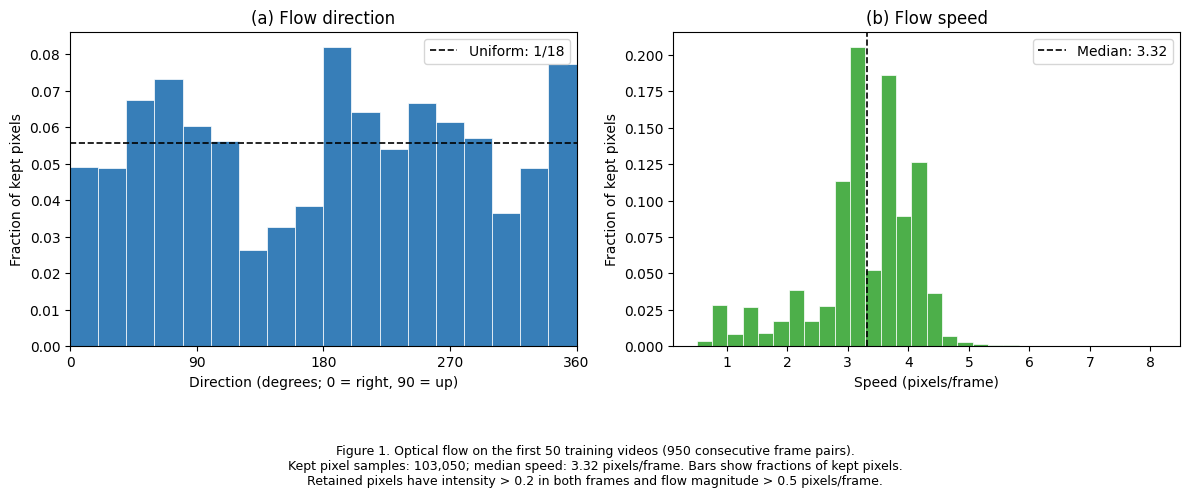

Figure 1. Optical flow on the first 50 training videos (950 consecutive frame pairs).
Kept pixel samples: 103,050; median speed: 3.32 pixels/frame. Bars show fractions of kept pixels.
Retained pixels have intensity > 0.2 in both frames and flow magnitude > 0.5 pixels/frame.


In [13]:
direction_edges = np.arange(0.0, 361.0, 20.0)
direction_counts, _ = np.histogram(
    flow_directions_deg, bins=direction_edges,
)
direction_fractions = direction_counts / num_kept

speed_counts, speed_edges = np.histogram(flow_speeds, bins=30)
speed_fractions = speed_counts / num_kept

assert direction_counts.sum() == num_kept
assert speed_counts.sum() == num_kept
assert np.isclose(direction_fractions.sum(), 1.0)
assert np.isclose(speed_fractions.sum(), 1.0)

figure1_caption = (
    "Figure 1. Optical flow on the first 50 training videos "
    "(950 consecutive frame pairs).\n"
    f"Kept pixel samples: {num_kept:,}; median speed: "
    f"{median_speed:.3g} pixels/frame. Bars show fractions of kept pixels.\n"
    "Retained pixels have intensity > 0.2 in both frames "
    "and flow magnitude > 0.5 pixels/frame."
)

flow_figure, flow_axes = plt.subplots(1, 2, figsize=(12, 5))

flow_axes[0].bar(
    direction_edges[:-1],
    direction_fractions,
    width=np.diff(direction_edges),
    align="edge",
    color="#377eb8",
    edgecolor="white",
    linewidth=0.5,
)
flow_axes[0].axhline(
    1.0 / 18.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Uniform: 1/18",
)
flow_axes[0].set(
    title="(a) Flow direction",
    xlabel="Direction (degrees; 0 = right, 90 = up)",
    ylabel="Fraction of kept pixels",
    xlim=(0, 360),
    xticks=[0, 90, 180, 270, 360],
)
flow_axes[0].legend()

flow_axes[1].bar(
    speed_edges[:-1],
    speed_fractions,
    width=np.diff(speed_edges),
    align="edge",
    color="#4daf4a",
    edgecolor="white",
    linewidth=0.5,
)
flow_axes[1].axvline(
    median_speed,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"Median: {median_speed:.3g}",
)
flow_axes[1].set(
    title="(b) Flow speed",
    xlabel="Speed (pixels/frame)",
    ylabel="Fraction of kept pixels",
)
flow_axes[1].legend()

flow_figure.text(
    0.5, 0.015, figure1_caption,
    ha="center", va="bottom", fontsize=9,
)
flow_figure.tight_layout(rect=(0, 0.18, 1, 1))
plt.show()

print(figure1_caption)

### Q2.1 — Training motion statistics

Figure 1(a) displays a histogram of optical-flow directions. We can observe that each direction range has samples; however, the bars are of different heights. Thus, the directions are not equally common in the examined training videos, and mirroring or rotation can change their relative frequencies. Nevertheless, transformed trajectories generally move in directions already represented in the data. These directions would therefore likely be familiar, although this does not guarantee that a model will successfully predict the transformed videos.

From Figure 1(b), a typical flow speed is around 3-4 pixels/frame, with a median of 3.32 pixels/frame. Scaling the unrounded median gives nominal displacement references of 6.64 and 9.95 pixels per observed step for 2x and 3x playback respectively. These are scaled references derived from the original measurements, rather than separately measured flow medians for faster playback.

Optical flow can be unreliable where digits overlap because the estimator assigns one displacement vector to each image location. If two overlapping digits have different motions, this vector may not represent either motion accurately. Such errors could affect both the histogram and the median speed. Depending on the degree of overlap and how many such examples occur, uncertainty remains regarding the size of this bias.

### Q2.2 — Effects of the transformations

For mirroring and rotation, the digit appearance changes, and the motion directions also change. Mirroring reverses the horizontal component of motion, while rotation turns each direction by 90°. However, the speeds remain the same. Thus, the flow-speed histogram should remain largely unchanged, while the direction distribution may be affected.

For speed-up, the digit's shape remains the same because we retain existing frames at larger intervals. However, the displacement between successive observations becomes much larger. Thus, this transformation changes the observed motion speeds while preserving the digit shapes.

These transformations provide useful controlled comparisons. Mirroring and rotation examine changes in appearance and orientation while preserving speed, whereas speed-up examines faster motion while preserving digit shape. Comparing the model's behavior under these transformations helps investigate whether failures are associated with appearance and orientation changes or with larger movements between observations.

### 13. Save Figure 1 and the underlying measurements

Save a high-resolution PNG, a compressed NumPy file containing the pooled samples, a JSON summary, per-pair sample counts, and the caption.

To revise labels or plotting choices, rerun the plotting and saving cells using the measurements already in memory. You can also restore the pooled samples from the saved NumPy file in a later session.

The saved JSON includes OpenCV's version and all Farneback settings. The per-pair counts make the pooling procedure auditable; they do not identify overlapping digits.

In [14]:
figure1_path = OUTPUT_DIR / "figure1_motion_statistics.png"
samples_path = OUTPUT_DIR / "figure1_flow_samples.npz"
summary_path = OUTPUT_DIR / "figure1_summary.json"
pair_counts_path = OUTPUT_DIR / "figure1_pair_counts.csv"
caption_path = OUTPUT_DIR / "figure1_caption.txt"

flow_figure.savefig(figure1_path, dpi=300, bbox_inches="tight")
np.savez_compressed(
    samples_path,
    directions_deg=flow_directions_deg,
    speeds_pixels_per_frame=flow_speeds,
)
flow_pair_counts.to_csv(pair_counts_path, index=False)
caption_path.write_text(figure1_caption, encoding="utf-8")

flow_summary = {
    "environment": {**environment, "opencv": cv2.__version__},
    "training_video_indices": list(range(NUM_FLOW_VIDEOS)),
    "num_frame_pairs": num_pairs,
    "kept_pixel_samples": num_kept,
    "median_speed_pixels_per_frame": median_speed,
    "scaled_2x_reference": 2 * median_speed,
    "scaled_3x_reference": 3 * median_speed,
    "scaled_reference_note": (
        "Multiples of the measured 1x median, not new flow measurements."
    ),
    "farneback_parameters": FARNEBACK_PARAMS,
    "selection": {
        "intensity_uint8_strictly_greater_than": 51,
        "intensity_required_in_both_frames_at_same_location": True,
        "flow_speed_strictly_greater_than": 0.5,
    },
    "direction_histogram": {
        "edges_degrees": direction_edges.tolist(),
        "counts": direction_counts.tolist(),
        "fractions": direction_fractions.tolist(),
    },
    "speed_histogram": {
        "edges_pixels_per_frame": speed_edges.tolist(),
        "counts": speed_counts.tolist(),
        "fractions": speed_fractions.tolist(),
    },
    "calculation_seconds": flow_seconds,
}
summary_path.write_text(
    json.dumps(flow_summary, indent=2),
    encoding="utf-8",
)

for saved_path in (
    figure1_path, samples_path, summary_path, pair_counts_path, caption_path,
):
    print("Saved:", saved_path)

print("Stage 3 measurements and Figure 1 saved.")

Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_motion_statistics.png
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_flow_samples.npz
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_summary.json
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_pair_counts.csv
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_caption.txt
Stage 3 measurements and Figure 1 saved.


## Stage 4: Model A implementation and correctness checks

**Goal:** implement the exact baseline, verify its parameter count and nine-step rollout, check the masked loss, and perform one diagnostic optimizer step.

The model created below is called `check_model`. It is disposable: official training will construct fresh models with seeds 0 and 1.

### 14. Define one ConvLSTM cell

Each cell stores a hidden state `h` and a memory state `c`. Its convolution takes the current input concatenated with the previous hidden state, and produces four groups of channels in the exact order `i, f, o, g`:

- Input gate `sigmoid(i)`: how much candidate memory to add.
- Forget gate `sigmoid(f)`: how much previous memory to keep.
- Output gate `sigmoid(o)`: how much memory to expose in the hidden state.
- Candidate `tanh(g)`: the proposed memory update.

The equations directly implement those in the handout. There are no peephole connections or additional layers. All convolutions keep PyTorch's default initialization, including their biases.

The seed helper will be reused when we set up full training. Setting a seed here initializes the diagnostic model reproducibly; official training resets the seed separately for each run.

In [15]:
import random
from torch import nn
import torch.nn.functional as F


def seed_everything(seed):
    """Seed the random-number generators used by this assignment."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels=64):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.gates = nn.Conv2d(
            in_channels=input_channels + hidden_channels,
            out_channels=4 * hidden_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=True,
        )

    def forward(self, current_input, state):
        previous_h, previous_c = state
        combined = torch.cat((current_input, previous_h), dim=1)
        i, f, o, g = self.gates(combined).chunk(4, dim=1)

        new_c = (
            torch.sigmoid(f) * previous_c
            + torch.sigmoid(i) * torch.tanh(g)
        )
        new_h = torch.sigmoid(o) * torch.tanh(new_c)
        return new_h, new_c

### 15. Define the complete forecaster and nine-step rollout

A frame changes shape as follows, with `B` denoting the batch size:

`(B, 1, 64, 64)` -> pixel unshuffle -> `(B, 16, 16, 16)` -> ConvLSTM 1 -> `(B, 64, 16, 16)` -> ConvLSTM 2 -> `(B, 64, 16, 16)` -> 1x1 convolution -> `(B, 16, 16, 16)` -> pixel shuffle and sigmoid -> `(B, 1, 64, 64)`.

Pixel unshuffle rearranges each 4x4 patch into channels without learning weights; pixel shuffle reverses the rearrangement. New hidden and memory states start at zero **inside every forward call**.

The forecaster accepts only the five observed frames. Targets are supplied separately to the loss function.

| Update | Input | Output used in the forecast? |
| --- | --- | --- |
| 1-4 | Observed frames 1-4 | No |
| 5 | Observed frame 5 | Yes: horizon 1 |
| 6-9 | Previous predicted frame | Yes: horizons 2-5 |

`return_trace=True` exposes the actual input/output tensors at each update for inspection. Normal training calls use the default `False`.

References: [pixel unshuffle](https://docs.pytorch.org/docs/2.11/generated/torch.nn.functional.pixel_unshuffle.html) and [Conv2d](https://docs.pytorch.org/docs/2.11/generated/torch.nn.Conv2d.html).

In [16]:
class ConvLSTMForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.cell1 = ConvLSTMCell(input_channels=16, hidden_channels=64)
        self.cell2 = ConvLSTMCell(input_channels=64, hidden_channels=64)
        self.readout = nn.Conv2d(64, 16, kernel_size=1, bias=True)

    def forward(self, inputs, return_trace=False):
        if inputs.ndim != 5 or tuple(inputs.shape[1:]) != (5, 1, 64, 64):
            raise ValueError("Expected inputs with shape (B, 5, 1, 64, 64).")
        if not inputs.is_floating_point():
            raise TypeError("Input frames must be floating-point tensors.")

        batch_size = inputs.shape[0]
        state_shape = (batch_size, 64, 16, 16)
        h1 = inputs.new_zeros(state_shape)
        c1 = inputs.new_zeros(state_shape)
        h2 = inputs.new_zeros(state_shape)
        c2 = inputs.new_zeros(state_shape)

        forecast_frames = []
        trace_inputs = []
        trace_outputs = []

        for step_index in range(9):
            if step_index < 5:
                frame = inputs[:, step_index]
            else:
                # Preserve the graph: never detach a fed-back prediction.
                frame = next_frame

            folded = F.pixel_unshuffle(frame, downscale_factor=4)
            h1, c1 = self.cell1(folded, (h1, c1))
            h2, c2 = self.cell2(h1, (h2, c2))
            next_frame = torch.sigmoid(
                F.pixel_shuffle(self.readout(h2), upscale_factor=4)
            )

            if step_index >= 4:
                forecast_frames.append(next_frame)

            if return_trace:
                trace_inputs.append(frame)
                trace_outputs.append(next_frame)

        forecasts = torch.stack(forecast_frames, dim=1)
        if return_trace:
            return forecasts, {
                "inputs": trace_inputs,
                "outputs": trace_outputs,
            }
        return forecasts

### 16. Define and check the masked training loss

For each video, first calculate the MSE at each horizon, then average over its **available** horizons. Finally average those per-video losses across the batch.

This gives a video with two targets the same overall weight as a video with five targets. Dividing the summed batch error by the total number of valid horizons would give the videos unequal weights.

In [17]:
def masked_video_mse(predictions, targets, target_mask):
    """Average over valid horizons within each video, then over videos."""
    if predictions.ndim != 5 or predictions.shape != targets.shape:
        raise ValueError("Predictions and targets need matching (B, H, C, Y, X) shapes.")
    if target_mask.shape != predictions.shape[:2]:
        raise ValueError("Expected target_mask with shape (B, H).")
    if target_mask.dtype != torch.bool:
        raise TypeError("target_mask must be boolean.")

    per_horizon_mse = (predictions - targets).square().mean(dim=(2, 3, 4))
    weights = target_mask.to(dtype=predictions.dtype)
    valid_counts = weights.sum(dim=1)
    if torch.any(valid_counts == 0):
        raise ValueError("Every video needs at least one valid target.")

    per_video_mse = (per_horizon_mse * weights).sum(dim=1) / valid_counts
    return per_video_mse.mean()


toy_predictions = torch.zeros(2, 5, 1, 2, 2)
toy_targets = torch.full_like(toy_predictions, 100.0)
toy_targets[0] = 1.0
toy_targets[1, :2] = 3.0
toy_mask = torch.tensor([
    [True, True, True, True, True],
    [True, True, False, False, False],
])

toy_loss = masked_video_mse(toy_predictions, toy_targets, toy_mask)
torch.testing.assert_close(toy_loss, torch.tensor(5.0))

print("Synthetic masked loss:", toy_loss.item())
print("Equal weighting and exclusion of unavailable targets: passed.")

Synthetic masked loss: 5.0
Equal weighting and exclusion of unavailable targets: passed.


### 17. Verify parameters, shapes, and actual rollout inputs

The expected parameter counts, including biases, are:

| Component | Calculation | Parameters |
| --- | --- | --- |
| ConvLSTM 1 | `256 * (16 + 64) * 3 * 3 + 256` | 184,576 |
| ConvLSTM 2 | `256 * (64 + 64) * 3 * 3 + 256` | 295,168 |
| Readout | `16 * 64 + 16` | 1,040 |
| **Total** | | **480,784** |

Inspect the rollout table against the handout's diagram. The checks verify that updates 1-5 use observations, updates 6-9 use the actual previous predicted tensors, and the returned forecast is exactly updates 5-9.

A repeated forward pass checks that state is reset between calls. Labels in the table refer to the normal-speed window starting at frame 1.

In [18]:
check_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed_everything(0)
check_model = ConvLSTMForecaster().to(check_device)

component_counts = {
    "ConvLSTM 1": sum(p.numel() for p in check_model.cell1.parameters()),
    "ConvLSTM 2": sum(p.numel() for p in check_model.cell2.parameters()),
    "Readout": sum(p.numel() for p in check_model.readout.parameters()),
}
assert component_counts == {
    "ConvLSTM 1": 184_576,
    "ConvLSTM 2": 295_168,
    "Readout": 1_040,
}
num_parameters = sum(
    p.numel() for p in check_model.parameters() if p.requires_grad
)
assert num_parameters == 480_784

check_windows = [
    make_window(train_videos[index], start=1, speed=1)
    for index in range(2)
]
check_inputs = torch.stack([item[0] for item in check_windows]).to(check_device)
check_targets = torch.stack([item[1] for item in check_windows]).to(check_device)
check_mask = torch.stack([item[2] for item in check_windows]).to(check_device)

check_model.eval()
with torch.no_grad():
    check_predictions, rollout_trace = check_model(
        check_inputs, return_trace=True,
    )
    repeated_predictions = check_model(check_inputs)

assert tuple(check_predictions.shape) == (2, 5, 1, 64, 64)
assert torch.isfinite(check_predictions).all()
assert torch.all((check_predictions >= 0) & (check_predictions <= 1))
assert len(rollout_trace["inputs"]) == len(rollout_trace["outputs"]) == 9

for step_index in range(5):
    assert torch.equal(
        rollout_trace["inputs"][step_index],
        check_inputs[:, step_index],
    )
for step_index in range(5, 9):
    assert (
        rollout_trace["inputs"][step_index]
        is rollout_trace["outputs"][step_index - 1]
    )

assert torch.equal(
    check_predictions,
    torch.stack(rollout_trace["outputs"][4:], dim=1),
)
torch.testing.assert_close(
    repeated_predictions, check_predictions, rtol=1e-5, atol=1e-6,
)

rollout_rows = []
for step_index in range(9):
    rollout_rows.append({
        "Update": step_index + 1,
        "Actual input": (
            f"Observed frame {step_index + 1}"
            if step_index < 5
            else f"Previous prediction of frame {step_index + 1}"
        ),
        "Predicts frame": step_index + 2,
        "Forecast use": (
            "Discarded" if step_index < 4
            else f"Horizon {step_index - 3}"
        ),
    })

display(pd.DataFrame(rollout_rows))
print("Device:", check_device)
if check_device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Parameters:", f"{num_parameters:,}")
print("Component counts:", component_counts)
print("Input shape:", tuple(check_inputs.shape))
print("Forecast shape:", tuple(check_predictions.shape))
print("Parameter, shape, range, rollout, and state-reset checks passed.")

,Update,Actual input,Predicts frame,Forecast use
0,1,Observed frame 1,2,Discarded
1,2,Observed frame 2,3,Discarded
2,3,Observed frame 3,4,Discarded
3,4,Observed frame 4,5,Discarded
4,5,Observed frame 5,6,Horizon 1
5,6,Previous prediction of frame 6,7,Horizon 2
6,7,Previous prediction of frame 7,8,Horizon 3
7,8,Previous prediction of frame 8,9,Horizon 4
8,9,Previous prediction of frame 9,10,Horizon 5


Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Parameters: 480,784
Component counts: {'ConvLSTM 1': 184576, 'ConvLSTM 2': 295168, 'Readout': 1040}
Input shape: (2, 5, 1, 64, 64)
Forecast shape: (2, 5, 1, 64, 64)
Parameter, shape, range, rollout, and state-reset checks passed.


### 18. Verify feedback gradients and one optimizer update

There are two separate checks:

1. **Feedback gradient:** compute a loss on only the final forecast horizon. Retain the gradient of the first predicted frame. A nonzero gradient there shows that later predictions depend differentiably on a fed-back prediction. Using a loss on every horizon would not establish this: the first prediction could receive a gradient directly from its own error.
2. **One optimizer update:** use the full masked loss with Adam at `1e-3`, verify finite gradients, and confirm that a parameter tensor changes.

`retain_grad()` is used only for this diagnostic. It does not change the architecture. We do not detach feedback or hidden states.

In [19]:
check_model.train()
check_model.zero_grad(set_to_none=True)

gradient_predictions, gradient_trace = check_model(
    check_inputs, return_trace=True,
)
first_predicted_frame = gradient_trace["outputs"][4]
first_predicted_frame.retain_grad()

final_horizon_loss = F.mse_loss(
    gradient_predictions[:, -1],
    check_targets[:, -1],
)
final_horizon_loss.backward()

feedback_gradient = first_predicted_frame.grad
assert feedback_gradient is not None, "Feedback frame has no gradient."
assert torch.isfinite(feedback_gradient).all()
feedback_gradient_sum = feedback_gradient.abs().sum().item()
assert feedback_gradient_sum > 0.0, "Gradient does not pass through feedback."

smoke_optimizer = torch.optim.Adam(check_model.parameters(), lr=1e-3)
smoke_optimizer.zero_grad(set_to_none=True)
weight_before = check_model.readout.weight.detach().clone()

smoke_predictions = check_model(check_inputs)
smoke_loss_before = masked_video_mse(
    smoke_predictions, check_targets, check_mask,
)
assert torch.isfinite(smoke_loss_before)
smoke_loss_before.backward()

for name, parameter in check_model.named_parameters():
    assert parameter.grad is not None, f"No gradient for {name}."
    assert torch.isfinite(parameter.grad).all(), f"Non-finite gradient for {name}."

smoke_optimizer.step()
assert all(
    torch.isfinite(parameter).all()
    for parameter in check_model.parameters()
)
weights_changed = not torch.equal(
    weight_before, check_model.readout.weight.detach(),
)
assert weights_changed, "Readout weights did not change."

check_model.eval()
with torch.no_grad():
    smoke_loss_after = masked_video_mse(
        check_model(check_inputs), check_targets, check_mask,
    )
assert torch.isfinite(smoke_loss_after)

stage4_summary = {
    "device": str(check_device),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if check_device.type == "cuda"
        else None
    ),
    "trainable_parameters": num_parameters,
    "component_parameters": component_counts,
    "input_shape": list(check_inputs.shape),
    "forecast_shape": list(check_predictions.shape),
    "rollout_updates": len(rollout_trace["inputs"]),
    "synthetic_masked_loss": toy_loss.item(),
    "feedback_gradient_absolute_sum": feedback_gradient_sum,
    "diagnostic_loss_before_update": smoke_loss_before.item(),
    "diagnostic_loss_after_update": smoke_loss_after.item(),
    "readout_weights_changed": weights_changed,
    "note": (
        "Diagnostic checks on two training videos; "
        "not a trained model or test-set performance result."
    ),
}
stage4_path = OUTPUT_DIR / "stage4_modelA_checks.json"
stage4_path.write_text(
    json.dumps(stage4_summary, indent=2),
    encoding="utf-8",
)

print(f"Feedback gradient absolute sum: {feedback_gradient_sum:.6e}")
print(f"Diagnostic loss before update: {smoke_loss_before.item():.6f}")
print(f"Diagnostic loss after update:  {smoke_loss_after.item():.6f}")
print("Readout weights changed:", weights_changed)
print("Feedback-gradient and optimizer checks passed.")
print("Saved:", stage4_path)

Feedback gradient absolute sum: 3.839766e-04
Diagnostic loss before update: 0.233166
Diagnostic loss after update:  0.229638
Readout weights changed: True
Feedback-gradient and optimizer checks passed.
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/stage4_modelA_checks.json


## Stage 5: Reproducible model A training and persistent checkpoints

**Goal:** start the required baseline training from fresh initialization, save completed epochs to Drive, and measure the training time.


### 19. Define the training protocol and random-window dataset

Each dataset access chooses one start uniformly from 1-11 and returns a normal-speed window. The DataLoader shuffles the 8,000 video indices without replacement, so each video contributes exactly once per epoch: **250 batches of 32 videos**.

The model initialization, shuffle generator, and window generator all use the run's seed. `num_workers=0` keeps window sampling in the main process, making its random state straightforward to save and restore.

No augmentation, scheduler, teacher forcing, gradient clipping, or mixed-precision context is added to model A.

In [20]:
from torch.utils.data import Dataset, DataLoader
from time import perf_counter

A_PROTOCOL = {
    "model": "A",
    "epochs": 30,
    "batch_size": 32,
    "learning_rate": 1e-3,
    "training_videos": 8000,
    "speed": 1,
    "allowed_start_frames": list(range(1, 12)),
    "precision": "float32",
}
TRAINING_DIR = PROJECT_DIR / "training_runs"
TRAINING_DIR.mkdir(parents=True, exist_ok=True)


class ModelATrainingDataset(Dataset):
    def __init__(self, base_videos, window_rng):
        self.base_videos = base_videos
        self.window_rng = window_rng
        self.starts = tuple(allowed_start_frames(speed=1))

    def __len__(self):
        return len(self.base_videos)

    def __getitem__(self, index):
        start = self.window_rng.choice(self.starts)
        return make_window(self.base_videos[index], start=start, speed=1)


assert len(train_videos) == A_PROTOCOL["training_videos"]
assert len(train_videos) // A_PROTOCOL["batch_size"] == 250
print(json.dumps(A_PROTOCOL, indent=2))
print("Persistent training folder:", TRAINING_DIR)

{
  "model": "A",
  "epochs": 30,
  "batch_size": 32,
  "learning_rate": 0.001,
  "training_videos": 8000,
  "speed": 1,
  "allowed_start_frames": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11
  ],
  "precision": "float32"
}
Persistent training folder: /content/drive/MyDrive/DL4STG_PA2/training_runs


### 20. Save and restore complete training state

Each checkpoint contains model weights, Adam's state, the completed epoch count, training history, hardware information, and random-generator states. Restoring only the weights would not reproduce continuation of the same training run.

A checkpoint is written to a temporary filename before replacing the previous `latest.pt`. Completed epochs are preserved if an interruption occurs during the next epoch. **An interrupted, unfinished epoch is repeated from its start on resume.**

`weights_only=False` is used to reload our own checkpoints because they include Python and NumPy random states as well as tensors.

References: [torch.load](https://docs.pytorch.org/docs/2.11/generated/torch.load.html) and [Generator state](https://docs.pytorch.org/docs/2.11/generated/torch.Generator.html).

In [21]:
def capture_random_states(window_rng, shuffle_generator):
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all(),
        "windows": window_rng.getstate(),
        "shuffle": shuffle_generator.get_state(),
    }


def restore_random_states(states, window_rng, shuffle_generator):
    random.setstate(states["python"])
    np.random.set_state(states["numpy"])
    torch.set_rng_state(states["torch_cpu"])
    torch.cuda.set_rng_state_all(states["torch_cuda"])
    window_rng.setstate(states["windows"])
    shuffle_generator.set_state(states["shuffle"])


def save_training_checkpoint(payload, path):
    temporary_path = path.with_name(path.name + ".tmp")
    torch.save(payload, temporary_path)
    temporary_path.replace(path)


def save_training_history(history, run_dir):
    history_path = run_dir / "history.csv"
    temporary_path = run_dir / "history.csv.tmp"
    pd.DataFrame(history).to_csv(temporary_path, index=False)
    temporary_path.replace(history_path)


print("Checkpoint and resume helpers defined.")

Checkpoint and resume helpers defined.


### 21. Define the baseline training runner

This function constructs a fresh `ConvLSTMForecaster`, seeds all generators, and creates Adam with the prescribed learning rate. If a checkpoint already exists for this seed, it loads the saved model, optimizer, and random states before continuing.

`through_epoch` is an **absolute stopping epoch**, not a number of additional epochs. For example, `through_epoch=30` resumes an epoch-1 checkpoint and performs epochs 2-30. Rerunning with `through_epoch=1` does not repeat an already completed epoch.

The saved training time is a GPU-synchronized wall-clock interval including window sampling, data loading, device transfers, forward/backward passes, and optimizer updates. Dataset download and checkpoint writing occur outside that interval. The first epoch is retained in the eventual 30-epoch timing average.

Hardware is recorded for every epoch. If a later resume uses a different GPU, that difference will remain visible in the history.

In [22]:
def train_model_a(seed, through_epoch=1):
    if seed not in (0, 1):
        raise ValueError("The assignment uses exactly seeds 0 and 1.")
    if not isinstance(through_epoch, int) or not 1 <= through_epoch <= 30:
        raise ValueError("through_epoch must be an integer from 1 to 30.")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a GPU runtime before starting training.")

    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    seed_everything(seed)
    window_rng = random.Random(seed)
    shuffle_generator = torch.Generator().manual_seed(seed)

    training_data = ModelATrainingDataset(train_videos, window_rng)
    loader = DataLoader(
        training_data,
        batch_size=A_PROTOCOL["batch_size"],
        shuffle=True,
        generator=shuffle_generator,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
    )
    assert len(loader) == 250

    # Fresh initialization; never reuse the Stage 4 diagnostic model.
    model = ConvLSTMForecaster().to(device=device, dtype=torch.float32)
    assert sum(p.numel() for p in model.parameters()) == 480_784
    optimizer = torch.optim.Adam(
        model.parameters(), lr=A_PROTOCOL["learning_rate"],
    )

    run_dir = TRAINING_DIR / f"A_seed{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    latest_path = run_dir / "latest.pt"
    final_path = run_dir / "final.pt"
    resume_path = (
        latest_path if latest_path.exists()
        else final_path if final_path.exists()
        else None
    )
    history = []
    completed_epochs = 0
    payload = None

    if resume_path is not None:
        payload = torch.load(
            resume_path, map_location="cpu", weights_only=False,
        )
        if payload["seed"] != seed or payload["protocol"] != A_PROTOCOL:
            raise ValueError("Checkpoint seed/protocol does not match this run.")
        model.load_state_dict(payload["model_state"])
        optimizer.load_state_dict(payload["optimizer_state"])
        history = payload["history"]
        completed_epochs = payload["completed_epochs"]
        assert len(history) == completed_epochs
        assert [row["epoch"] for row in history] == list(
            range(1, completed_epochs + 1)
        )
        restore_random_states(
            payload["random_states"], window_rng, shuffle_generator,
        )
        print(f"Resuming A, seed {seed}, after epoch {completed_epochs}.")
    else:
        print(f"Starting A, seed {seed}, from fresh initialization.")

    model.train()
    for epoch in range(completed_epochs + 1, through_epoch + 1):
        torch.cuda.synchronize()
        epoch_started = perf_counter()
        loss_sum = torch.zeros((), device=device)
        seen_videos = 0

        for batch_index, (inputs, targets, mask) in enumerate(loader, start=1):
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            predictions = model(inputs)
            loss = masked_video_mse(predictions, targets, mask)
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Non-finite loss at epoch {epoch}, batch {batch_index}."
                )
            loss.backward()
            optimizer.step()

            batch_size = inputs.shape[0]
            loss_sum += loss.detach() * batch_size
            seen_videos += batch_size
            if batch_index % 50 == 0:
                print(
                    f"Seed {seed} | epoch {epoch}/30 | "
                    f"batch {batch_index}/{len(loader)}"
                )

        epoch_loss = loss_sum.item() / seen_videos
        torch.cuda.synchronize()
        epoch_seconds = perf_counter() - epoch_started
        assert seen_videos == 8000
        if not np.isfinite(epoch_loss):
            raise FloatingPointError("Non-finite mean epoch loss.")

        history.append({
            "epoch": epoch,
            "training_mse": epoch_loss,
            "epoch_seconds": epoch_seconds,
            "videos": seen_videos,
            "batches": len(loader),
            "gpu": gpu_name,
            "torch": str(torch.__version__),
        })
        completed_epochs = epoch
        payload = {
            "format_version": 1,
            "seed": seed,
            "protocol": dict(A_PROTOCOL),
            "completed_epochs": completed_epochs,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
            "random_states": capture_random_states(
                window_rng, shuffle_generator,
            ),
            "environment": {**environment, "gpu_name": gpu_name},
            "timing_scope": (
                "GPU-synchronized training epoch including loading/transfers; "
                "excluding dataset download and checkpoint writes."
            ),
        }
        save_training_checkpoint(payload, latest_path)
        if completed_epochs == 30:
            save_training_checkpoint(payload, final_path)
        save_training_history(history, run_dir)
        print(
            f"Epoch {epoch} saved | training MSE {epoch_loss:.6f} | "
            f"{epoch_seconds:.2f} seconds"
        )

    # Regenerate the readable history even when no new epoch was needed.
    save_training_history(history, run_dir)
    if completed_epochs == 30 and not final_path.exists():
        save_training_checkpoint(payload, final_path)
    mean_epoch_seconds = float(np.mean([
        row["epoch_seconds"] for row in history
    ]))
    print(f"Completed epochs for seed {seed}: {completed_epochs}/30")
    print(f"Mean recorded epoch time: {mean_epoch_seconds:.2f} seconds")
    print("Latest checkpoint:", latest_path)

    return {
        "seed": seed,
        "completed_epochs": completed_epochs,
        "history": history,
        "mean_epoch_seconds": mean_epoch_seconds,
        "latest_checkpoint": str(latest_path),
        "final_checkpoint": str(final_path) if final_path.exists() else None,
    }

### 22. Run seed 0 through its first official epoch and verify the checkpoint

**This cell starts training.** It runs one complete epoch: all 8,000 training videos, 250 batches, and one randomly sampled window per video. The epoch counts toward the required 30.

After saving, reload the checkpoint on the CPU and verify the recorded progress. The model and optimizer will be reconstructed from that checkpoint when we continue.

If the call is interrupted before the first epoch finishes, rerunning starts that unfinished epoch again. Once an epoch is saved, rerunning this cell does not repeat it.

In [23]:
A_seed0_status = train_model_a(seed=0, through_epoch=1)

saved_checkpoint = torch.load(
    A_seed0_status["latest_checkpoint"],
    map_location="cpu",
    weights_only=False,
)
assert saved_checkpoint["seed"] == 0
assert saved_checkpoint["completed_epochs"] == A_seed0_status["completed_epochs"]
assert saved_checkpoint["protocol"] == A_PROTOCOL
assert len(saved_checkpoint["history"]) == saved_checkpoint["completed_epochs"]
assert "optimizer_state" in saved_checkpoint
assert "random_states" in saved_checkpoint
assert "model_state" in saved_checkpoint

print("Checkpoint reload verification passed.")
display(pd.DataFrame(A_seed0_status["history"]))
print(
    "Rough 30-epoch time at the recorded rate:",
    f"{30 * A_seed0_status['mean_epoch_seconds'] / 60:.1f} minutes per seed",
)
print("This estimate excludes checkpoint writing and may change after warm-up.")
del saved_checkpoint

Starting A, seed 0, from fresh initialization.
Seed 0 | epoch 1/30 | batch 50/250
Seed 0 | epoch 1/30 | batch 100/250
Seed 0 | epoch 1/30 | batch 150/250
Seed 0 | epoch 1/30 | batch 200/250
Seed 0 | epoch 1/30 | batch 250/250
Epoch 1 saved | training MSE 0.046045 | 6.14 seconds
Completed epochs for seed 0: 1/30
Mean recorded epoch time: 6.14 seconds
Latest checkpoint: /content/drive/MyDrive/DL4STG_PA2/training_runs/A_seed0/latest.pt
Checkpoint reload verification passed.


,epoch,training_mse,epoch_seconds,videos,batches,gpu,torch
0,1,0.046045,6.138702,8000,250,NVIDIA A100-SXM4-40GB,2.11.0+cu130


Rough 30-epoch time at the recorded rate: 3.1 minutes per seed
This estimate excludes checkpoint writing and may change after warm-up.


### 23. Complete the required 30 epochs for both seeds

In [24]:
A_seed0_status = train_model_a(seed=0, through_epoch=30)
A_seed1_status = train_model_a(seed=1, through_epoch=30)

training_summary_rows = []
for status in (A_seed0_status, A_seed1_status):
    assert status["completed_epochs"] == 30
    assert len(status["history"]) == 30
    assert status["final_checkpoint"] is not None
    assert Path(status["final_checkpoint"]).is_file()
    assert all(row["videos"] == 8000 for row in status["history"])
    assert all(row["batches"] == 250 for row in status["history"])

    training_summary_rows.append({
        "seed": status["seed"],
        "epochs": status["completed_epochs"],
        "final_training_mse": status["history"][-1]["training_mse"],
        "mean_epoch_seconds": status["mean_epoch_seconds"],
        "total_training_seconds": sum(
            row["epoch_seconds"] for row in status["history"]
        ),
        "gpu": "; ".join(sorted({row["gpu"] for row in status["history"]})),
        "final_checkpoint": status["final_checkpoint"],
    })

A_training_summary = pd.DataFrame(training_summary_rows)
summary_path = OUTPUT_DIR / "modelA_training_summary.csv"
A_training_summary.to_csv(summary_path, index=False)
display(A_training_summary[[
    "seed", "epochs", "final_training_mse", "mean_epoch_seconds", "gpu",
]])
print("Both model A seeds have completed 30 epochs.")
print("Training summary saved to:", summary_path)


Resuming A, seed 0, after epoch 1.
Seed 0 | epoch 2/30 | batch 50/250
Seed 0 | epoch 2/30 | batch 100/250
Seed 0 | epoch 2/30 | batch 150/250
Seed 0 | epoch 2/30 | batch 200/250
Seed 0 | epoch 2/30 | batch 250/250
Epoch 2 saved | training MSE 0.039686 | 6.22 seconds
Seed 0 | epoch 3/30 | batch 50/250
Seed 0 | epoch 3/30 | batch 100/250
Seed 0 | epoch 3/30 | batch 150/250
Seed 0 | epoch 3/30 | batch 200/250
Seed 0 | epoch 3/30 | batch 250/250
Epoch 3 saved | training MSE 0.038615 | 6.17 seconds
Seed 0 | epoch 4/30 | batch 50/250
Seed 0 | epoch 4/30 | batch 100/250
Seed 0 | epoch 4/30 | batch 150/250
Seed 0 | epoch 4/30 | batch 200/250
Seed 0 | epoch 4/30 | batch 250/250
Epoch 4 saved | training MSE 0.037095 | 6.16 seconds
Seed 0 | epoch 5/30 | batch 50/250
Seed 0 | epoch 5/30 | batch 100/250
Seed 0 | epoch 5/30 | batch 150/250
Seed 0 | epoch 5/30 | batch 200/250
Seed 0 | epoch 5/30 | batch 250/250
Epoch 5 saved | training MSE 0.035304 | 6.13 seconds
Seed 0 | epoch 6/30 | batch 50/250
Se

,seed,epochs,final_training_mse,mean_epoch_seconds,gpu
0,0,30,0.022911,6.113199,NVIDIA A100-SXM4-40GB
1,1,30,0.021866,6.088139,NVIDIA A100-SXM4-40GB


Both model A seeds have completed 30 epochs.
Training summary saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/modelA_training_summary.csv


## Stage 6: Baseline evaluation, Table 2, and Figure 2

**Goal:** evaluate both final-epoch model A checkpoints and the two deterministic reference predictors on all 1,000 test videos, then inspect three seed-0 prediction examples.

### 24. Define fixed-window evaluation and load final checkpoints

All predictors receive the same test windows in original video order. Blank predicts zero everywhere; Copy-last repeats input frame 5 for all five horizons. They have no trainable parameters.

For each test video and horizon, calculate MSE over the 64x64 pixels. Average these per-video values over all 1,000 videos. This also avoids giving the final smaller batch the same weight as a full batch.

We record inference time for later tables. Each batch is moved to the GPU before timing starts. GPU synchronization brackets the forward pass, and the 32 batch times are summed. Target processing, metric calculation, and saving are outside inference timing.

The checkpoint loader requires epoch 30 and the correct seed. It never loads the Stage 4 diagnostic model.

In [25]:
from torch.utils.data import Dataset, DataLoader
from time import perf_counter

EVAL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FINAL_TRAINING_DIR = PROJECT_DIR / "training_runs"
assert list(test_videos.indices) == list(range(9000, 10000))


class OriginalTestWindows(Dataset):
    def __init__(self, base_videos):
        self.base_videos = base_videos

    def __len__(self):
        return len(self.base_videos)

    def __getitem__(self, index):
        return make_window(self.base_videos[index], start=1, speed=1)


class BlankPredictor(nn.Module):
    def forward(self, inputs):
        return torch.zeros_like(inputs)


class CopyLastPredictor(nn.Module):
    def forward(self, inputs):
        return inputs[:, -1:].expand(-1, 5, -1, -1, -1)


original_test_loader = DataLoader(
    OriginalTestWindows(test_videos),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=EVAL_DEVICE.type == "cuda",
)
assert len(original_test_loader) == 32


def load_final_model_a(seed):
    checkpoint_path = FINAL_TRAINING_DIR / f"A_seed{seed}" / "final.pt"
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False,
    )
    assert checkpoint["seed"] == seed
    assert checkpoint["completed_epochs"] == 30
    assert checkpoint["protocol"]["model"] == "A"
    model = ConvLSTMForecaster().to(EVAL_DEVICE)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def evaluate_original_predictor(predictor, keep_predictions=False):
    predictor = predictor.to(EVAL_DEVICE).eval()
    mse_batches = []
    prediction_batches = []
    inference_seconds = 0.0

    with torch.no_grad():
        for inputs, targets, mask in original_test_loader:
            inputs = inputs.to(EVAL_DEVICE, non_blocking=True)
            targets = targets.to(EVAL_DEVICE, non_blocking=True)
            mask = mask.to(EVAL_DEVICE, non_blocking=True)
            assert mask.all(), "The original 1x windows have five targets."

            if EVAL_DEVICE.type == "cuda":
                torch.cuda.synchronize()
            started = perf_counter()
            predictions = predictor(inputs)
            if EVAL_DEVICE.type == "cuda":
                torch.cuda.synchronize()
            inference_seconds += perf_counter() - started

            assert predictions.shape == targets.shape
            assert torch.isfinite(predictions).all()
            per_video_mse = (predictions - targets).square().mean(dim=(2, 3, 4))
            mse_batches.append(per_video_mse.cpu())
            if keep_predictions:
                prediction_batches.append(predictions.cpu())

    per_video_mse = torch.cat(mse_batches, dim=0)
    assert tuple(per_video_mse.shape) == (1000, 5)
    horizon_mse = per_video_mse.double().mean(dim=0)
    return {
        "mse_h": horizon_mse.tolist(),
        "E5": horizon_mse.mean().item(),
        "E2": horizon_mse[:2].mean().item(),
        "parameters": sum(p.numel() for p in predictor.parameters()),
        "inference_seconds": inference_seconds,
        "per_video_mse": per_video_mse,
        "predictions": (
            torch.cat(prediction_batches, dim=0)
            if keep_predictions else None
        ),
    }


print("Evaluation device:", EVAL_DEVICE)
print("Test videos:", len(test_videos), "| Batches:", len(original_test_loader))

Evaluation device: cuda
Test videos: 1000 | Batches: 32


### 25. Evaluate both seeds and references, save predictions, and build Table 2

Model A's metric entries are formatted as **mean (seed 0, seed 1)**. Deterministic reference predictors have one value. Parameter counts are exact integers; the model A count is shown in the same seed format for completeness.

In [26]:
A_original_results = {}
for seed in (0, 1):
    model = load_final_model_a(seed)
    result = evaluate_original_predictor(model, keep_predictions=True)
    assert result["parameters"] == 480_784
    A_original_results[seed] = result

    cache_path = OUTPUT_DIR / f"baseline_A_seed{seed}_original_1x.pt"
    torch.save({
        "seed": seed,
        "start": 1,
        "speed": 1,
        "original_video_indices": torch.arange(9000, 10000),
        "predictions": result["predictions"],
        "per_video_mse": result["per_video_mse"],
    }, cache_path)
    print(f"Seed {seed}: E(5) = {result['E5']:.6f}; saved {cache_path}")
    del model

reference_results = {
    "Blank": evaluate_original_predictor(BlankPredictor()),
    "Copy-last": evaluate_original_predictor(CopyLastPredictor()),
}


def format_error(value):
    return f"{value:.2e}" if abs(value) < 1e-3 else f"{value:#.3g}"


def format_seed_error(value0, value1):
    mean = (value0 + value1) / 2
    return f"{format_error(mean)} ({format_error(value0)}, {format_error(value1)})"


table2_rows = [{"Model": "A"}]
for horizon in range(5):
    table2_rows[0][f"MSE{horizon + 1}"] = format_seed_error(
        A_original_results[0]["mse_h"][horizon],
        A_original_results[1]["mse_h"][horizon],
    )
table2_rows[0]["E(5)"] = format_seed_error(
    A_original_results[0]["E5"], A_original_results[1]["E5"],
)
table2_rows[0]["Parameters"] = "480784 (480784, 480784)"

for name, result in reference_results.items():
    row = {"Model": name}
    row.update({
        f"MSE{horizon + 1}": format_error(result["mse_h"][horizon])
        for horizon in range(5)
    })
    row["E(5)"] = format_error(result["E5"])
    row["Parameters"] = str(result["parameters"])
    table2_rows.append(row)

table2 = pd.DataFrame(table2_rows)
display(table2)
table2_path = OUTPUT_DIR / "table2.csv"
table2.to_csv(table2_path, index=False)


def metric_record(result):
    return {
        key: result[key]
        for key in ("mse_h", "E5", "E2", "parameters", "inference_seconds")
    }


table2_metrics = {
    "test_video_indices": list(range(9000, 10000)),
    "start": 1,
    "speed": 1,
    "batch_size": 32,
    "inference_device": str(EVAL_DEVICE),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if EVAL_DEVICE.type == "cuda" else None
    ),
    "inference_timing_scope": (
        "Sum of synchronized forward-pass wall times, "
        "starting after each batch is on the device."
    ),
    "model_A": {
        str(seed): metric_record(A_original_results[seed]) for seed in (0, 1)
    },
    "references": {
        name: metric_record(result) for name, result in reference_results.items()
    },
}
metrics_path = OUTPUT_DIR / "table2_metrics.json"
metrics_path.write_text(json.dumps(table2_metrics, indent=2), encoding="utf-8")
print("Table 2 saved to:", table2_path)
print("Full-precision metrics saved to:", metrics_path)

Seed 0: E(5) = 0.022823; saved /content/drive/MyDrive/DL4STG_PA2/outputs/baseline_A_seed0_original_1x.pt
Seed 1: E(5) = 0.021947; saved /content/drive/MyDrive/DL4STG_PA2/outputs/baseline_A_seed1_original_1x.pt


,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),Parameters
0,A,"0.0170 (0.0178, 0.0163)","0.0207 (0.0212, 0.0201)","0.0230 (0.0234, 0.0226)","0.0247 (0.0250, 0.0245)","0.0265 (0.0266, 0.0263)","0.0224 (0.0228, 0.0219)","480784 (480784, 480784)"
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


Table 2 saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table2.csv
Full-precision metrics saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table2_metrics.json


### 26. Preview candidate test videos for Figure 2

Figure 2 needs three test videos, with at least one showing overlapping digits.

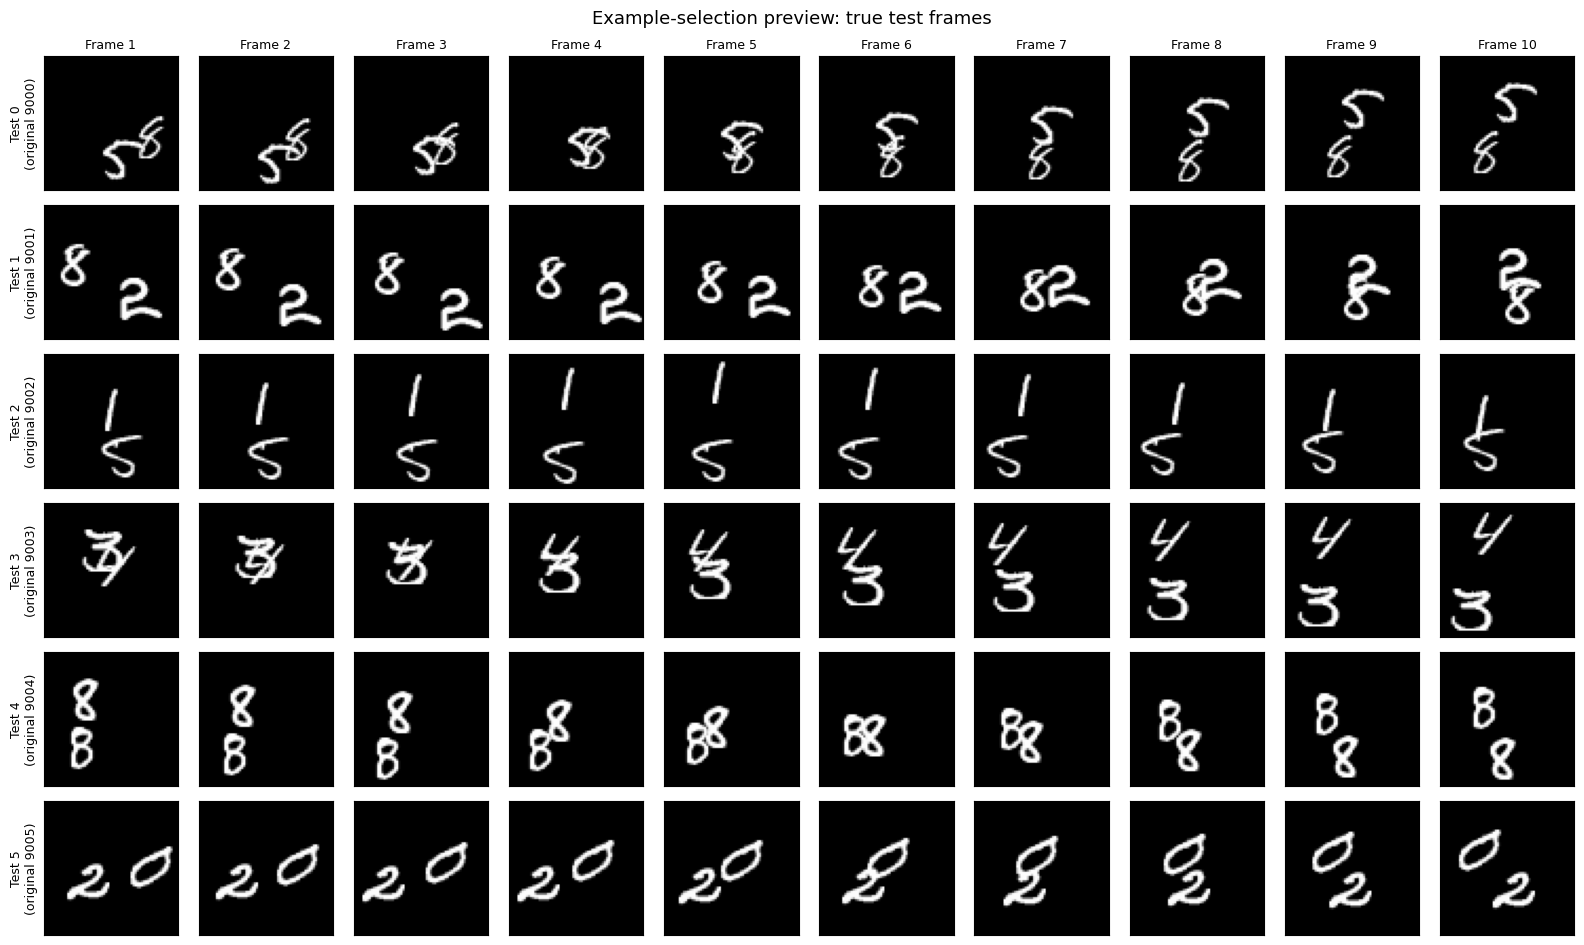

In [27]:
PREVIEW_TEST_IDS = [0, 1, 2, 3, 4, 5]
assert all(0 <= index < len(test_videos) for index in PREVIEW_TEST_IDS)

preview_figure, preview_axes = plt.subplots(
    len(PREVIEW_TEST_IDS), 10,
    figsize=(16, 1.6 * len(PREVIEW_TEST_IDS)),
    squeeze=False,
)
for row, test_index in enumerate(PREVIEW_TEST_IDS):
    true_frames = test_videos[test_index][:10, 0]
    for frame_index in range(10):
        ax = preview_axes[row, frame_index]
        ax.imshow(true_frames[frame_index].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"Frame {frame_index + 1}", fontsize=9)
    preview_axes[row, 0].set_ylabel(
        f"Test {test_index}\n(original {9000 + test_index})",
        fontsize=9,
    )
preview_figure.suptitle("Example-selection preview: true test frames", fontsize=13)
preview_figure.tight_layout()
plt.show()


### 27. Generate Figure 2 from seed 0


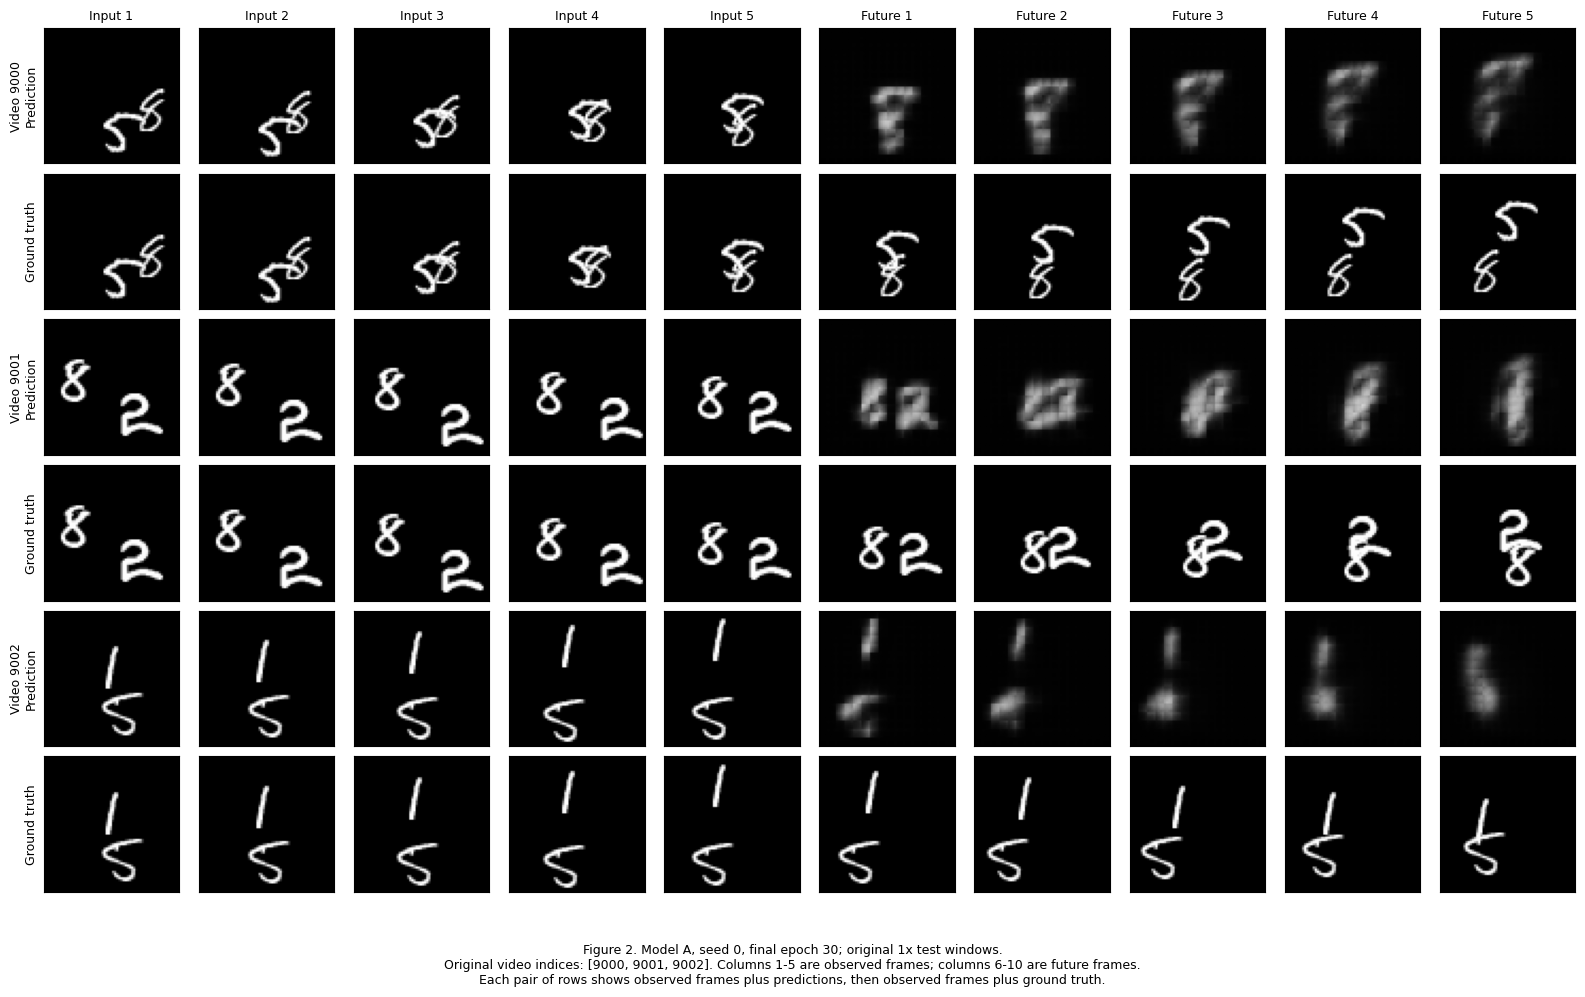

Figure 2 saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/figure2_modelA_examples.png
Confirm visually that a selected example includes overlapping digits.


In [28]:
FIGURE2_TEST_IDS = [0, 1, 2]
assert len(FIGURE2_TEST_IDS) == 3 and len(set(FIGURE2_TEST_IDS)) == 3
assert all(0 <= index < len(test_videos) for index in FIGURE2_TEST_IDS)

seed0_predictions = A_original_results[0]["predictions"]
assert tuple(seed0_predictions.shape) == (1000, 5, 1, 64, 64)
figure2, figure2_axes = plt.subplots(6, 10, figsize=(16, 10), squeeze=False)

for example_number, test_index in enumerate(FIGURE2_TEST_IDS):
    true_frames = test_videos[test_index][:10, 0]
    predicted_frames = seed0_predictions[test_index, :, 0]
    for column in range(10):
        prediction_image = (
            true_frames[column] if column < 5
            else predicted_frames[column - 5]
        )
        for offset, image in [(0, prediction_image), (1, true_frames[column])]:
            row = 2 * example_number + offset
            ax = figure2_axes[row, column]
            ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(
                    f"Input {column + 1}" if column < 5 else f"Future {column - 4}",
                    fontsize=9,
                )
    original_index = 9000 + test_index
    figure2_axes[2 * example_number, 0].set_ylabel(
        f"Video {original_index}\nPrediction", fontsize=9,
    )
    figure2_axes[2 * example_number + 1, 0].set_ylabel(
        "Ground truth", fontsize=9,
    )

figure2_caption = (
    "Figure 2. Model A, seed 0, final epoch 30; original 1x test windows.\\n"
    f"Original video indices: {[9000 + index for index in FIGURE2_TEST_IDS]}. "
    "Columns 1-5 are observed frames; columns 6-10 are future frames.\\n"
    "Each pair of rows shows observed frames plus predictions, "
    "then observed frames plus ground truth."
).replace("\\n", "\n")
figure2.text(0.5, 0.01, figure2_caption, ha="center", va="bottom", fontsize=9)
figure2.tight_layout(rect=(0, 0.09, 1, 1))
figure2_path = OUTPUT_DIR / "figure2_modelA_examples.png"
figure2.savefig(figure2_path, dpi=300, bbox_inches="tight")
(OUTPUT_DIR / "figure2_caption.txt").write_text(figure2_caption, encoding="utf-8")
(OUTPUT_DIR / "figure2_selection.json").write_text(
    json.dumps({
        "test_subset_indices": FIGURE2_TEST_IDS,
        "original_video_indices": [9000 + index for index in FIGURE2_TEST_IDS],
        "seed": 0,
        "start": 1,
        "speed": 1,
    }, indent=2),
    encoding="utf-8",
)
plt.show()
print("Figure 2 saved to:", figure2_path)
print("Confirm visually that a selected example includes overlapping digits.")

### Q2.3 - Model A's reach
Pixel unshuffle changes the image from a 64x64 spatial grid into a 16x16 spatial grid, putting each 4x4 patch into channels.

Therefore, moving one position along the folded grid corresponds to four original pixels.

A 3x3 convolution uses a position and its immediate neighbours; and thus,information can move one folded-grid position horizontally or vertically or diagonally through that convolution.

Model A has two stacked ConvLSTM layers. The current frame enters layer 1, whose new hidden state enters layer 2. Therefore, information can move one position through layer 1, then another position through layer 2. This is essentially 2 of the folded-grid positions along an axis.

Moreover, due to recurrence the layers receive the previous hidden states as well. Considering everything, we have three paths: from current input folded frame to layers 1 through 2, from previous hidden state of layer 1 to layers 1 through 2, and from previous hidden state of layer 2 through layer 2 only.

The longest path contains two 3x3 convolutions, and as discussed these correspond to 4 pixels per position for each convolution. Therefore, we have 8 pixels per time step.

However, do note that as we mentioned above, the information can travel diagonally as well. That yields 11.3 pixels per time step along said axis.

### Q2.4 - Baseline Performance Discussion
Model A consistently outperforms the two reference predictors, namely Blank and Copy-Last, at 1x speed.

Table 2 shows that model A has a mean E(5) of 0.0224, compared with 0.0426 for Blank and 0.0641 for Copy-Last; and model A has much lower MSE at every forecast horizon compared to the two.

However, its error increases steadily from MSE1 = 0.0170 to MSE5 = 0.0265. Both seeds show this trend, and this is understandable because of error accumulation in the autoregressive nature of predictions. Blank's error remains approximately constant, while Copy-last becomes progressively worse.

When the digits overlap (refer to figure 2) we see blurry blobs rather than distinct and clear digit shapes. Merging and loss of digit identity is observed. But these poor blurry predictions are not necessarily caused due to overlap, as can be seen in video examples without overlapping digits.

### Q2.5 - Predictions before testing the baseline
According to my understanding of Model A, I predict that it will fail both the mirror and rotation tests. Although Figure 1 shows broad coverage of optical flow directions, the architecture does not explicitly enforce consistency under mirroring or rotation. Thus, broad direction coverage alone may not be sufficient for consistent predictions on transformed videos.

For speed transformations, I expect noticeable degradation at 2x and the clearest breakdown at 3x. Typical training speeds are around 3-4 pixels/frame, whereas the scaled median references are approximately 6.64 and 9.95 pixels/frame. The 2x reference is within the model's eight-pixel reach along each axis, but these larger displacements are less familiar from training. At 3x, near-axis-aligned movement can exceed that reach, although some diagonal movements remain within the spatial support. Therefore, unfamiliar speeds and limited reach may both contribute to increased blur, misplaced predictions and loss of digit identity